# Figure showing the dominant uncertainty by location for each impact

In [2]:
import xarray as xr
import xagg as xa
import numpy as np
import pandas as pd
import geopandas as gpd
import os
import re
import glob
import string
import zarr
import warnings
from tqdm.notebook import tqdm

import matplotlib as mpl
from matplotlib import pyplot as plt
from matplotlib import colors as mcolors
from cartopy import crs as ccrs
import cmocean

import distributed

from funcs_support import get_filepaths,get_params,utility_save,utility_print
from funcs_readregs import load_dmgfs
from funcs_processing import calc_uncerts
from funcs_plot import plot_map, vals_to_color_triangle, plot_dmgfs

dir_list = get_params()
extra_fonts = {'lato':mpl.font_manager.FontProperties(fname=dir_list['aux']+'fonts/Lato-Regular.ttf'),
 'lato-bold':mpl.font_manager.FontProperties(fname=dir_list['aux']+'fonts/Lato-Bold.ttf')}






In [3]:
params_proc = {'mortality':{'varname':'tassumpoly','geo_typ':'impact-regions','shp_fn':'impact-region','popwght':False},
               'gdppc':{'varname':'tassumpoly','geo_typ':'adm1','shp_fn':'country-fixed','popwght':True},
               'payroll':{'varname':'tasmaxbinF','geo_typ':'adm2-us','shp_fn':'UScounties','popwght':True}}

proc_names = {'mortality':'mort. rate',
              'gdppc':'GDP p.c. growth',
              'payroll':'payroll'}

proc_full_names = {'mortality':'All-cause mortality\n(Carleton et al. 2022)',
                   'gdppc':'GDP per capita growth\n(Burke, Hsiang, and\nMiguel 2015)',
                   'payroll':'Payroll\n(Behrer et al., 2021)'}

idxs = {'impact-regions':{'hierid':'locid'},
        'adm1':{'CNTRY_NAME':'locid'},
        'adm2-us':{'FIPS':'locid'}}

gwl = 2

reg_x = 0.5 #bbox to find region around location

nsubplt_cols = 2
add_regunc = False

uncert_typ = '13runs9mods_noMERRA2'
#uncert_typ = '13runs9mods'




In [4]:
subplt_locs = {'mortality':{'Tokyo':[35.652832,139.839478],
                            'Kolkata':[22.572645, 88.363892],
              'Dallas':[32.779167, -96.808891],
              'Cape Town':[-33.918861,18.423300]},
               'gdppc':{'Germany':[50.555809, 9.680845],
                            'India':[22.572645, 83.363892],
              'USA':[32.779167, -96.808891],
              'South Africa':[-33.918861,18.423300]},
               'payroll':{'Seattle':[47.608013, -122.335167],
                            'New York':[40.730610,-73.935242],
              'Dallas':[32.779167, -96.808891],
              'Chicago':[41.881832,-87.623177]}}


In [5]:
def load_impacts(proc,uncert_typ,subplot_regs_all):
    
    # Load impacts projections
    fns = np.sort(glob.glob(f'{dir_list['proc']}impact_projs/{proc}/d{proc}*.zarr'))
    def load_impact(fn):
        ds_tmp = xr.open_zarr(fn,consolidated=False)
        ds_tmp = ds_tmp.set_coords('locid') # Should be coordinate, instead of concatenated variable
        ds_tmp = ds_tmp.assign_coords({'model':(('idv'),[re.split(r'\_',re.split(r'\/',fn)[-1])[2]]*ds_tmp.sizes['idv'])})
    
        ds_tmp['exprun'] = ds_tmp['experiment']+ds_tmp['run']
        ds_tmp = ds_tmp.reset_index('idv')
        ds_tmp = ds_tmp.set_index(idv = ['model','exprun'])
        return ds_tmp
    
    with warnings.catch_warnings():
        # Silence zarr warnings related to the /.done flags used
        warnings.filterwarnings('ignore')
        dss = xr.concat([load_impact(fn) for fn in fns],
                    dim='idv',join='outer')
    
    dss = dss.set_index({'poly_idx':'locid'}).rename({'poly_idx':'locid'})
    
    # Figure out how many BCD-ME members reach a given GWL
    gwl_counter = dss.maxgwl.load().reset_index('idv').groupby(['model','maxgwl']).count()
    gwl_counter = gwl_counter.sel(maxgwl = gwl_counter.maxgwl.values[::-1]).cumsum('maxgwl')
    #print(gwl_counter)
    
    dss_tmp = dss
    
    if 'noMERRA2' in uncert_typ:
        dss_tmp = dss_tmp.sel(proj_base = [pb for pb in dss_tmp.proj_base.values if pb != 'MERRA2'])
    
    if '13runs9mods' in uncert_typ:
        max_gwl = 3
        nruns = 13
        
        gwlmods = gwl_counter.sel(maxgwl=3)
        proc_mods = gwlmods.isel(model = gwlmods>=nruns).model.values
        
        dss_tmp = dss_tmp.isel(idv = dss.maxgwl>=max_gwl).groupby('model').map(lambda x: x.isel(idv=slice(0, nruns)))
        dss_tmp = dss_tmp.isel(idv=[m in proc_mods for m in dss_tmp.model.values]).chunk({'idv':-1})
    
    dss_tmp = dss_tmp.unstack('idv')['d'+proc]
    dss_tmp = dss_tmp.chunk({'model':-1,'exprun':-1})
    
    # Get mean over all needed locations
    dss_tmp = dss_tmp.sel(locid = subplt_regs_all.locid.values).load()

    return dss_tmp

Procesing mortality...


/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/pyogrio/raw.py:200: RuntimeWarning: /glade/u/home/schwarzwald/projects/impact_uncertainty/aux_data/geo_data/impact-region.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(


NameError: name 'stacked_plot' is not defined

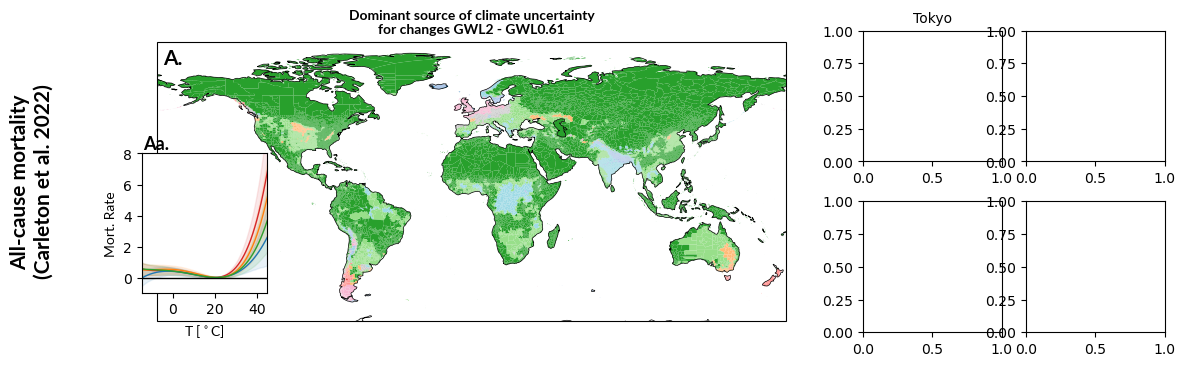

In [11]:
save_fig = True
output_fn = dir_list['figs']+'Figure2'
uncert_typ = '13runs9mods'
if 'noMERRA2' not in uncert_typ:
    output_fn = output_fn+'_wMERRA2'

fig = plt.figure(figsize=(13,14))

gs = plt.GridSpec(nrows=2*len(params_proc) + (len(params_proc) -1),
                  ncols= 4 + nsubplt_cols + 1,
                  width_ratios=[*([1]*4),0.2,*([1]*nsubplt_cols)],
                  height_ratios = [1,1,*([0.05,1,1]*(len(params_proc)-1))],
                  hspace = 0.4,wspace=0.2)

for row_idx,proc in enumerate(params_proc):
    print(f'Procesing {proc}...')
    #-------------------------
    # Load plot data ---------
    #-------------------------
    
    # Load partitioned uncertainty
    fn = f'{dir_list['proc']}uncert_parts/uncert_parts_{proc}.zarr'
    uncerts = xr.open_zarr(fn).load()
    uncerts = uncerts.set_index(poly_idx = 'locid').rename({'poly_idx':'locid'})

    # XX A typo somehow XX
    if proc == 'payroll':
        uncerts['sample'] = [re.sub('10mods','9mods',src) for src in uncerts.sample.values]
    
    # Load shapefile
    gdf = gpd.read_file(f'{dir_list['aux']}geo_data/{params_proc[proc]['shp_fn']}.shp')
    gdf['geometry'] = gdf.make_valid()
    
    
    if params_proc[proc]['geo_typ'] == 'impact-regions':
        # Remove Antarctica
        gdf = gdf.query('ISO != "ATA"')
    elif params_proc[proc]['geo_typ'] == 'adm1':
        gdf = gdf.query('CNTRY_NAME != "Antarctica"')
    elif params_proc[proc]['geo_typ'] == 'adm2-us':
        # Remove Alaska and Hawaii
        gdf = gdf.iloc[[sn not in ['Alaska','Hawaii'] for sn in gdf.STATE_NAME.values]]
    
    # Name merging dimension 'locid'
    gdf = gdf.rename(idxs[params_proc[proc]['geo_typ']],axis=1)

    # Get regions for subplot
    # All regions that touch +/- reg_x of the central coordinate
    subplt_regs = {name:gdf.cx[(lon-reg_x):(lon+reg_x),(lat-reg_x):(lat+reg_x)]
                    for name,(lat,lon) in subplt_locs[proc].items()}
    subplt_regs_all = pd.concat([lc for name,lc in subplt_regs.items()])

    # Load raw change in impacts
    dss_tmp = load_impacts(proc,uncert_typ,subplt_regs_all)

    if proc == 'gdppc':
        # TODO turn this into an extra-subsets dict by proc
        dss_tmp = dss_tmp.sel(timeframe = 'allyears')
        uncerts = uncerts.sel(timeframe = 'allyears')
    
    #-------------------------
    # Map panel --------------
    #-------------------------
    if params_proc[proc]['geo_typ'] == 'adm2-us':
        # Only use part of the horizontal grid spec for the smaller counties map
        ax_map = fig.add_subplot(gs[(row_idx*2 + row_idx):((row_idx+1)*2 + row_idx),1:4],projection=ccrs.PlateCarree())
    else: 
        ax_map = fig.add_subplot(gs[(row_idx*2 + row_idx):((row_idx+1)*2 + row_idx),0:4],projection=ccrs.PlateCarree())

    
    plot_data = (uncerts.
                 sel(typ='norm',gwl=gwl,sample=uncert_typ).
                 to_dataarray().to_dataset(name='relvar'))
    # Turn scenario, model, internal into color triangle colors
    plot_data['colors'] = xr.DataArray(data=vals_to_color_triangle(plot_data['relvar'],
                                                                dim='variable',
                                                                col_names = {'r':'uncint',
                                                                             'g':'uncobs',
                                                                             'b':'uncmod'}),
                                            dims=['locid'])
    
    # Add to geodataframe
    plot_data = pd.merge(gdf,
                      (plot_data[['colors','locid']].to_dataframe().reset_index()),
                      on='locid')
    
    # Plot
    plot_data.plot(color=plot_data.colors,ax=ax_map)
    
    # Annotations
    ax_map.coastlines(linewidth=0.5)
    ax_map.annotate(string.ascii_uppercase[row_idx]+'.',(0.01,0.975),xycoords = 'axes fraction',
                fontweight='bold',fontsize=15,va='top',font=extra_fonts['lato-bold'])
    
    if row_idx == 0:
        ax_map.set_title('Dominant source of climate uncertainty\nfor changes GWL'+str(gwl)+' - GWL0.61',
                         fontsize=15,font=extra_fonts['lato-bold'])

    # Row labels
    if proc == 'payroll':
        row_ann_pos = (-0.375,0.5)
    else:
        row_ann_pos = (-0.2,0.5)
    ax_map.annotate(proc_full_names[proc],
                    row_ann_pos,xycoords = 'axes fraction',
                    fontweight='bold',fontsize=15,va='center',ha='center',
                    rotation=90,font=extra_fonts['lato-bold'])
    
    #-------------------------
    # Damage function panels -
    #-------------------------
    if proc == 'payroll':
        inset_coords = (-0.175,0.05,0.25,0.5)
    else:
        inset_coords = (-0.025,0.1,0.2,0.5)
    ax_dmgf = ax_map.inset_axes(inset_coords)

    dmgfs = load_dmgfs(proc)
    if 'noMERRA2' in uncert_typ:
        dmgfs = dmgfs.sel(proj_base = [pb for pb in dmgfs.proj_base.values if pb != 'MERRA2'])
    
    ax_dmgf = plot_dmgfs(dmgfs,proc,simple=True,ax=ax_dmgf)

    # Subplot lettering
    if proc == 'payroll':
        ax_dmgf.annotate(string.ascii_uppercase[row_idx]+'a.',(0.01,1.11),xycoords = 'axes fraction',
                fontweight='bold',fontsize=13,va='bottom',font=extra_fonts['lato-bold'])
    else:
        ax_dmgf.annotate(string.ascii_uppercase[row_idx]+'a.',(0.01,1.01),xycoords = 'axes fraction',
                fontweight='bold',fontsize=13,va='bottom',font=extra_fonts['lato-bold'])

    if proc == 'payroll':
        ax_dmgf.set_xlabel(r'T [$^\circ$F]',font=extra_fonts['lato'])
    else:
        ax_dmgf.set_xlabel(r'T [$^\circ$C]',font=extra_fonts['lato'])
    ax_dmgf.set_ylabel(proc_names[proc].title(),font=extra_fonts['lato'])

    if proc == 'payroll':
        ax_dmgf.ticklabel_format(axis='y',style='sci',scilimits = (0,0))
                
    #-------------------------
    # Reference varpart panels 
    #-------------------------
    # --- Right-hand subplot slots ---
    axes = [fig.add_subplot(gs[row_idx*2 + (subplt_idx // nsubplt_cols) + row_idx,
                               4 + 1 + (subplt_idx % nsubplt_cols)],
                            zorder = 2)
            for subplt_idx in range(len(subplt_locs[proc]))]
    
    # --- Helper: midpoint of subplot edge ---
    def edge_point(ax):
        bb = ax.get_position()  # in figure fraction
        return (bb.x0, (bb.y0 + bb.y1) / 2)
        #return (bb.x0, bb.y1)
        
    # --- Loop over explicitly assigned locations ---
    bbox_params = {'facecolor':'w','edgecolor':'none','pad':1.5}
    for plt_idx, (name, (lat, lon)), ax in zip(range(len(subplt_locs[proc])), subplt_locs[proc].items(), axes):
        # Title + dummy plot
        ax.set_title(name,
                     bbox = bbox_params,
                     zorder=5,
                     fontsize=10)
        # Get regions around the desired location
        regs_tmp = gdf.cx[(lon-reg_x):(lon+reg_x),(lat-reg_x):(lat+reg_x)]
        plot_data = xr.merge([uncerts.sel(locid=subplt_regs[name].locid.values,
                                          sample = uncert_typ),
                              dss_tmp.sel(locid = subplt_regs[name].locid.values)],
                             compat = 'override')
        plot_data = plot_data.sel(gwl=slice(1,2.5))
        plot_data = plot_data.mean('locid')
    
        if add_regunc:
            plot_data_tmp = plot_data.sel(typ='norm')[['uncreg','uncobs','uncmod','uncint']]
        else:
            plot_data_tmp = plot_data.sel(typ='norm')[['uncobs','uncmod','uncint']]
        ax = stacked_plot(plot_data_tmp/plot_data_tmp.to_dataarray().sum('variable'),
                     ax=ax,add_legend=False,
                         plot_type='line')
        ax.set_ylim([0,1])
    
        ax2 = ax.twinx()
        # Plot mean change + 95% IQR
        plot_data[f'd{proc}'].mean(['proj_base','model','exprun']).plot(color='k',linewidth=2)
        #rng_clim = np.sqrt(plot_data.sel(typ='raw')[['uncobs','uncmod','uncint']].to_dataarray().sum('variable'))
        #rng_all = np.sqrt(plot_data.sel(typ='raw')[['uncreg','uncobs','uncmod','uncint']].to_dataarray().sum('variable'))
    
        for q in [0.025,0.975]:
            plot_data[f'd{proc}'].quantile(q,['proj_base','model','exprun']).plot(color='k',linestyle='--')
        #(plot_data['meanl']+rng_all).plot(color='k',linestyle=':')
        #(plot_data['meanl']-rng_all).plot(color='k',linestyle=':')

        if proc == 'mortality':
            ax2.set_ylim([-20,80])
        elif proc == 'gdppc':
            ax2.set_ylim([-10,6])
        ax2.grid()
    
        # Leftmost subplots get left yaxis label
        if plt_idx % nsubplt_cols == 0:
            ax.set_ylabel('Frac. contr. to var.',fontsize=8,bbox=bbox_params,
                          font=extra_fonts['lato'])
        else:
            ax.set_ylabel('')
    
        # Rightmost subplots get right yaxis label
        if (plt_idx + 1) % nsubplt_cols == 0:
            ax2.set_ylabel(f'Change in {proc_names[proc]}',fontsize=8,font=extra_fonts['lato'])
        else:
            ax2.set_ylabel('')
    
        # Subplots to the right of the first column get no left yaxis labels
        if plt_idx % nsubplt_cols > 0:
            ax.set_yticklabels([])
        # Subplots to the left of the last column get no right yaxis labels
        if (plt_idx + 1) % nsubplt_cols > 0:
            ax2.set_yticklabels([])
    
        # Xlabel only on bottom row
        if plt_idx >= nsubplt_cols: 
            ax.set_xlabel(r'GWL [$^\circ$C]',fontsize=8,font=extra_fonts['lato'])
        else:
            ax.set_xlabel('')
        ax2.set_xlabel('')
        ax2.set_title('')
    
        ax.tick_params(axis='both', labelsize=8)
        ax2.tick_params(axis='both', labelsize=8)
    
        # Sublot lettering
        ax.annotate(string.ascii_uppercase[row_idx]+string.ascii_lowercase[plt_idx+1]+'.',
                    (0.01,1.025),xycoords = 'axes fraction',
                    fontweight='bold',fontsize=10,va='bottom',font=extra_fonts['lato-bold'])
    
    
        # Map point → figure coordinates
        disp = ax_map.transData.transform((lon, lat))  # PlateCarree input
        map_fig = fig.transFigure.inverted().transform(disp)
    
        # Subplot edge anchor
        anchor_fig = edge_point(ax)
    
        # Draw leader line
        line = plt.Line2D(
            [map_fig[0], anchor_fig[0]],
            [map_fig[1], anchor_fig[1]],
            transform=fig.transFigure,
            color="k",
            lw=0.3,
            zorder=1,
        )
        fig.lines.append(line)


if save_fig:
    utility_print(output_fn)



/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/pyogrio/raw.py:200: RuntimeWarning: /glade/u/home/schwarzwald/projects/impact_uncertainty/aux_data/geo_data/impact-region.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(


/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/extra_figs/uncert_part_map_dmortality_GWL2.pdf saved!
/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/extra_figs/uncert_part_map_dmortality_GWL2.png saved!


ValueError: Could not automatically create PandasIndex for coord 'timeframe' with 0 dimensions. Please explicitly set the index using `set_xindex`.

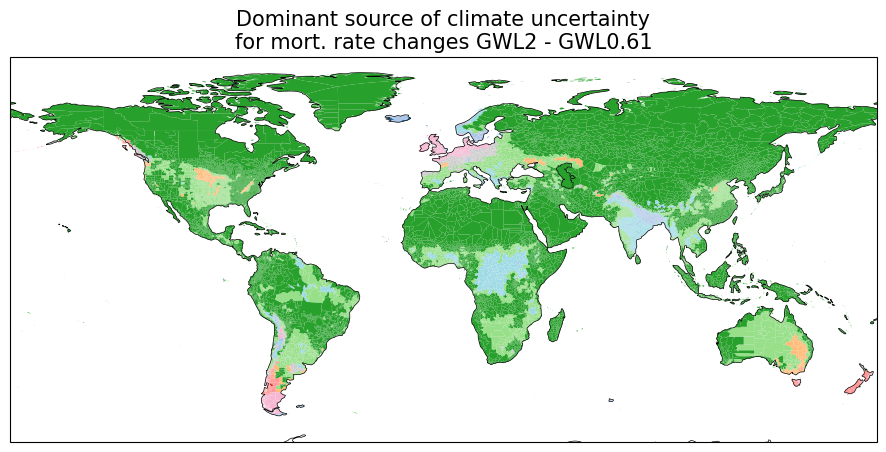

<Figure size 1200x500 with 0 Axes>

In [12]:
save_fig = True

uncert_typ = '13runs9mods'

# Now, just the map 
for proc in ['mortality','gdppc','payroll']:
    fig = plt.figure(figsize=(12,5))
    #-------------------------
    # Load plot data ---------
    #-------------------------
    
    # Load partitioned uncertainty
    fn = f'{dir_list['proc']}uncert_parts/uncert_parts_{proc}.zarr'
    uncerts = xr.open_zarr(fn).load()
    uncerts = uncerts.set_index(poly_idx = 'locid').rename({'poly_idx':'locid'})

    # XX A typo somehow XX
    if proc == 'payroll':
        uncerts['sample'] = [re.sub('10mods','9mods',src) for src in uncerts.sample.values]
    
    # Load shapefile
    gdf = gpd.read_file(f'{dir_list['aux']}geo_data/{params_proc[proc]['shp_fn']}.shp')
    gdf['geometry'] = gdf.make_valid()
    
    
    if params_proc[proc]['geo_typ'] == 'impact-regions':
        # Remove Antarctica
        gdf = gdf.query('ISO != "ATA"')
    elif params_proc[proc]['geo_typ'] == 'adm1':
        gdf = gdf.query('CNTRY_NAME != "Antarctica"')
    elif params_proc[proc]['geo_typ'] == 'adm2-us':
        # Remove Alaska and Hawaii
        gdf = gdf.iloc[[sn not in ['Alaska','Hawaii'] for sn in gdf.STATE_NAME.values]]
    
    # Name merging dimension 'locid'
    gdf = gdf.rename(idxs[params_proc[proc]['geo_typ']],axis=1)

    # Get regions for subplot
    # All regions that touch +/- reg_x of the central coordinate
    subplt_regs = {name:gdf.cx[(lon-reg_x):(lon+reg_x),(lat-reg_x):(lat+reg_x)]
                    for name,(lat,lon) in subplt_locs[proc].items()}
    subplt_regs_all = pd.concat([lc for name,lc in subplt_regs.items()])

    # Load raw change in impacts
    dss_tmp = load_impacts(proc,uncert_typ,subplt_regs_all)

    if proc == 'gdppc':
        # TODO turn this into an extra-subsets dict by proc
        dss_tmp = dss_tmp.sel(timeframe = 'allyears')
        uncerts = uncerts.sel(timeframe = 'allyears')

    
    #-------------------------
    # Map panel --------------
    #-------------------------
    ax_map = plt.subplot(projection=ccrs.PlateCarree())
   
    plot_data = (uncerts.
                 sel(typ='norm',gwl=gwl,sample=uncert_typ).
                 to_dataarray().to_dataset(name='relvar'))
    # Turn scenario, model, internal into color triangle colors
    plot_data['colors'] = xr.DataArray(data=vals_to_color_triangle(plot_data['relvar'],
                                                                dim='variable',
                                                                col_names = {'r':'uncint',
                                                                             'g':'uncobs',
                                                                             'b':'uncmod'}),
                                            dims=['locid'])
    
    # Add to geodataframe
    plot_data = pd.merge(gdf,
                      (plot_data[['colors','locid']].to_dataframe().reset_index()),
                      on='locid')
    
    # Plot
    plot_data.plot(color=plot_data.colors,ax=ax_map)
    
    # Annotations
    ax_map.coastlines(linewidth=0.5)
    #ax_map.annotate(string.ascii_uppercase[row_idx]+'.',(0.01,0.975),xycoords = 'axes fraction',
    #            fontweight='bold',fontsize=15,va='top',font=extra_fonts['lato-bold'])
    

    ax_map.set_title('Dominant source of climate uncertainty\nfor '+proc_names[proc]+' changes GWL'+str(gwl)+' - GWL0.61',
                         fontsize=15)#font=extra_fonts['lato-bold'])

    if save_fig:
        utility_print(f'{dir_list['figs']}extra_figs/uncert_part_map_d{proc}_GWL{str(gwl)}')

/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/pyogrio/raw.py:200: RuntimeWarning: /glade/u/home/schwarzwald/projects/impact_uncertainty/aux_data/geo_data/impact-region.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(


/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/extra_figs/uncert_part_map_dmortality_GWL2.pdf saved!
/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/extra_figs/uncert_part_map_dmortality_GWL2.png saved!
/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/extra_figs/uncert_part_map_dgdppc_GWL2.pdf saved!
/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/extra_figs/uncert_part_map_dgdppc_GWL2.png saved!
/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/extra_figs/uncert_part_map_dpayroll_GWL2.pdf saved!
/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/extra_figs/uncert_part_map_dpayroll_GWL2.png saved!


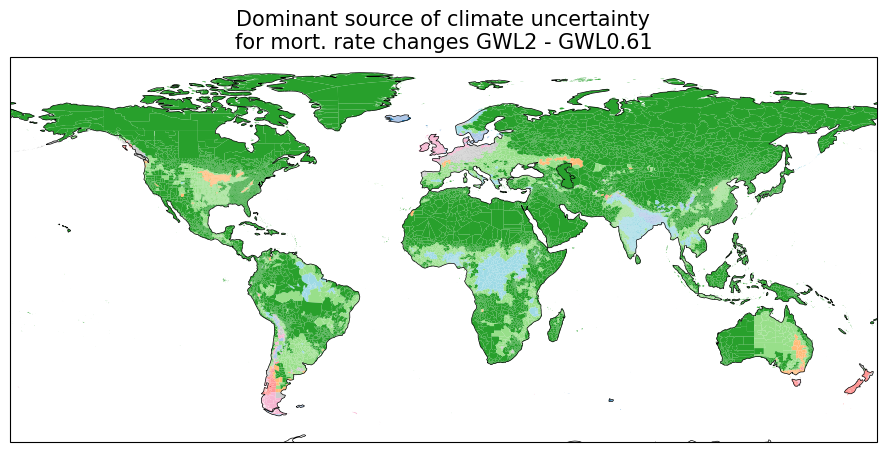

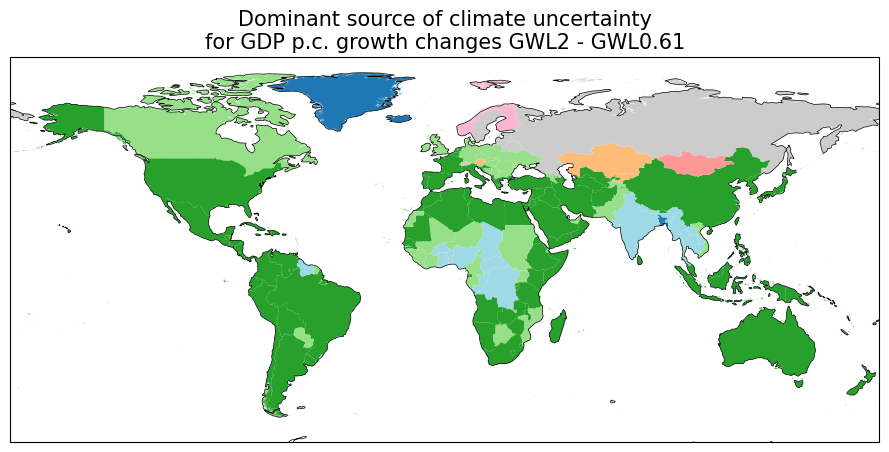

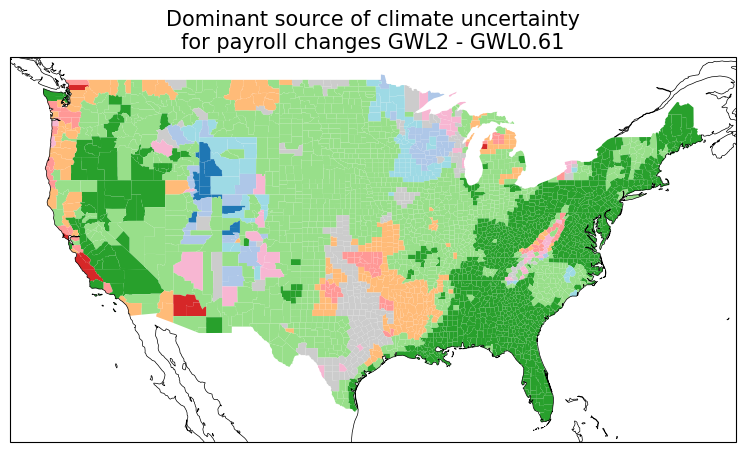

In [8]:
save_fig = True

# Now, just the map 
for proc in ['mortality','gdppc','payroll']:
    fig = plt.figure(figsize=(12,5))
    #-------------------------
    # Load plot data ---------
    #-------------------------
    
    # Load partitioned uncertainty
    fn = f'{dir_list['proc']}uncert_parts/uncert_parts_{proc}.zarr'
    uncerts = xr.open_zarr(fn).load()
    uncerts = uncerts.set_index(poly_idx = 'locid').rename({'poly_idx':'locid'})

    # XX A typo somehow XX
    if proc == 'payroll':
        uncerts['sample'] = [re.sub('10mods','9mods',src) for src in uncerts.sample.values]
    
    # Load shapefile
    gdf = gpd.read_file(f'{dir_list['aux']}geo_data/{params_proc[proc]['shp_fn']}.shp')
    gdf['geometry'] = gdf.make_valid()
    
    
    if params_proc[proc]['geo_typ'] == 'impact-regions':
        # Remove Antarctica
        gdf = gdf.query('ISO != "ATA"')
    elif params_proc[proc]['geo_typ'] == 'adm1':
        gdf = gdf.query('CNTRY_NAME != "Antarctica"')
    elif params_proc[proc]['geo_typ'] == 'adm2-us':
        # Remove Alaska and Hawaii
        gdf = gdf.iloc[[sn not in ['Alaska','Hawaii'] for sn in gdf.STATE_NAME.values]]
    
    # Name merging dimension 'locid'
    gdf = gdf.rename(idxs[params_proc[proc]['geo_typ']],axis=1)

    # Get regions for subplot
    # All regions that touch +/- reg_x of the central coordinate
    subplt_regs = {name:gdf.cx[(lon-reg_x):(lon+reg_x),(lat-reg_x):(lat+reg_x)]
                    for name,(lat,lon) in subplt_locs[proc].items()}
    subplt_regs_all = pd.concat([lc for name,lc in subplt_regs.items()])

    # Load raw change in impacts
    dss_tmp = load_impacts(proc,uncert_typ,subplt_regs_all)

    #if proc == 'gdppc':
    #    # TODO turn this into an extra-subsets dict by proc
    #    dss_tmp = dss_tmp.sel(timeframe = 'allyears')
    #    uncerts = uncerts.sel(timeframe = 'allyears')

    
    #-------------------------
    # Map panel --------------
    #-------------------------
    ax_map = plt.subplot(projection=ccrs.PlateCarree())
   
    plot_data = (uncerts.
                 sel(typ='norm',gwl=gwl,sample=uncert_typ).
                 to_dataarray().to_dataset(name='relvar'))
    # Turn scenario, model, internal into color triangle colors
    plot_data['colors'] = xr.DataArray(data=vals_to_color_triangle(plot_data['relvar'],
                                                                dim='variable',
                                                                col_names = {'r':'uncint',
                                                                             'g':'uncobs',
                                                                             'b':'uncmod'}),
                                            dims=['locid'])
    
    # Add to geodataframe
    plot_data = pd.merge(gdf,
                      (plot_data[['colors','locid']].to_dataframe().reset_index()),
                      on='locid')
    
    # Plot
    plot_data.plot(color=plot_data.colors,ax=ax_map)
    
    # Annotations
    ax_map.coastlines(linewidth=0.5)
    #ax_map.annotate(string.ascii_uppercase[row_idx]+'.',(0.01,0.975),xycoords = 'axes fraction',
    #            fontweight='bold',fontsize=15,va='top',font=extra_fonts['lato-bold'])
    

    ax_map.set_title('Dominant source of climate uncertainty\nfor '+proc_names[proc]+' changes GWL'+str(gwl)+' - GWL0.61',
                         fontsize=15)#font=extra_fonts['lato-bold'])

    if save_fig:
        utility_print(f'{dir_list['figs']}extra_figs/uncert_part_map_d{proc}_GWL{str(gwl)}')

In [9]:
uncerts

<xarray.Dataset> Size: 4MB
Dimensions:  (sample: 3, typ: 2, locid: 3141, gwl: 8)
Coordinates:
  * sample   (sample) <U20 240B 'allruns' '13runs9mods' '13runs9mods_noMERRA2'
  * typ      (typ) object 16B 'raw' 'norm'
  * locid    (locid) StringDType() 50kB '27077' '53019' ... '02068' '08014'
  * gwl      (gwl) float64 64B 0.61 1.0 1.5 2.0 2.5 3.0 3.5 4.0
Data variables:
    uncint   (sample, typ, locid, gwl) float64 1MB nan 1.501e-07 ... 0.03573
    uncmod   (sample, typ, locid, gwl) float64 1MB nan 5.832e-08 ... 0.2587
    uncobs   (sample, typ, locid, gwl) float64 1MB nan 1.027e-07 ... 0.7056
Attributes:
    SOURCE:       4_partition_uncertainty.ipynb
    DESCRIPTION:  Uncertainty partitioning of projections of payroll between ...

In [15]:
def stacked_lineplot(plot_data,ax = None,
                add_legend = False,
                 plot_type = 'bar', #'bar' or 'line'
                 xdim = 'gwl',
                uncert_colors = {'uncmod':'tab:blue',
                                 'uncsce':'green',
                                 'uncint':'tab:orange',
                                 'uncobs':'tab:green',
                                 'uncreg':'lightgrey'},
                unc_source_names = {'uncint':'internal var.',
                                    'uncmod':'model unc.',
                                    'uncobs':'observational unc.',
                                    'uncreg':'regression unc.',
                                    'uncsce':'scenario unc.'},
                    var_order = ['uncobs','uncint','uncmod','uncsce','uncreg']
                    ):

    if ax is None:
        ax = plt.subplot()

    varlist = [var for var in plot_data if var in uncert_colors]
    varlist = [var for var in var_order if var in varlist]

    # Plot mean change line
    ax.plot(plot_data.gwl.values, plot_data['meanl'], color="k", lw=2, label=r'Mean $\Delta$ mort.')

    # Start from the mean line
    lower = plot_data['meanl'].values.copy()
    upper = plot_data['meanl'].values.copy()
    
    # Add each uncertainty source
    for unc in varlist:
        # half goes above, half below
        mag = np.sqrt(plot_data[unc]) / 2
        ax.fill_between(plot_data[unc].gwl.values, 
                        lower, lower-mag,
            color = uncert_colors[unc],
            label=unc
        )
        ax.fill_between(plot_data[unc].gwl.values, 
                        upper, upper+mag,
            color = uncert_colors[unc],
            label=unc
        )
    
        lower -= mag
        upper += mag

    if add_legend:
        ax.legend(bbox_to_anchor=(1,1))

    ax.set_xlabel(r'GWL [$^\circ$C]')
    #ax.set_ylabel('Frac. contribution to total variance')

    return ax

def stacked_plot(plot_data,ax = None,
                add_legend = False,
                 plot_type = 'bar', #'bar' or 'line'
                 xdim = 'gwl',
                uncert_colors = {'uncmod':'tab:blue',
                                 'uncsce':'green',
                                 'uncint':'tab:red',
                                 'uncobs':'tab:green',
                                 'uncreg':'lightgrey'},
                unc_source_names = {'uncint':'internal var.',
                                    'uncmod':'model unc.',
                                    'uncobs':'observational unc.',
                                    'uncreg':'regression unc.',
                                    'uncsce':'scenario unc.'}):

    if ax is None:
        ax = plt.subplot()
    
    varlist = [var for var in plot_data if var in uncert_colors]
    
    bottom = np.zeros(plot_data.sizes[xdim])
    for var in varlist:
        plot_values = plot_data[var]

        if plot_type == 'bar':
            p = ax.bar(np.arange(0,plot_data.sizes[xdim]),
                       plot_values, label=unc_source_names[var],
                       color = uncert_colors[var],
                       bottom=bottom)
        elif plot_type == 'line':
            ax.fill_between(plot_values[xdim],
                            bottom,
                            bottom + plot_values,
                            color = uncert_colors[var],
                            label = unc_source_names[var])
        bottom += plot_values

    
    if plot_type == 'bar':
        ax.set_xticks(np.arange(0,plot_data.sizes[xdim]),
                      plot_values.gwl.values)
    elif plot_type == 'line':
        ax.set_xlim([plot_data[xdim].values[0],plot_data[xdim].values[-1]])

    

    if add_legend:
        ax.legend(bbox_to_anchor=(1,1))

    ax.set_xlabel(r'GWL [$^\circ$C]')
    ax.set_ylabel('Frac. contribution to total variance')

    return ax